**Market Analysis and Stock Segmentation Using RFM**

In [3]:
!pip install yfinance lxml -q

In [4]:

import os, json, platform, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import scipy, sklearn
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

In [5]:
START, END = '2021-01-01', '2025-01-01'
LAST_DAY = pd.Timestamp(END) - pd.Timedelta(days=1)
SEED = 42
BASE, WIN, MULT = 20, 60, 2
os.makedirs('data', exist_ok=True); os.makedirs('outputs', exist_ok=True)

1.1 Ticker selection and data acquisition

1.1 Retrieve and store the S&P 500 ticker list

In [6]:

import yfinance as yf
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
sp500_df = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})[0]
sp500_df['yf_ticker'] = sp500_df['Symbol'].str.replace('.', '-', regex=False)
sp500_df['retrieval_date'] = str(pd.Timestamp.today().date())
sp500_df.to_csv('data/sp500_constituents.csv', index=False)

1.1  prepare the ticker list

In [7]:
tickers = sp500_df['yf_ticker'].tolist()
print('Tickers requested:', len(tickers), '| retrieval date:', sp500_df['retrieval_date'].iloc[0])

Tickers requested: 503 | retrieval date: 2026-11-22


1.1 Download share prices and the S&P 500 benchmark

In [8]:
raw = yf.download(tickers, start=START, end=END, auto_adjust=False, progress=False)
bench_raw = yf.download('^GSPC', start=START, end=END, auto_adjust=False, progress=False)
if isinstance(bench_raw.columns, pd.MultiIndex):
    bench_raw.columns = bench_raw.columns.get_level_values(0)

raw['Adj Close'].to_csv('data/adj_close.csv')
raw['Close'].to_csv('data/close.csv')
raw['Volume'].to_csv('data/volume.csv')
bench_raw[['Close', 'Adj Close']].to_csv('data/gspc.csv')

info = {'download_date': str(pd.Timestamp.today().date()), 'yfinance': yf.__version__,
        'tickers_requested': len(tickers), 'start': START, 'end_exclusive': END,
        'last_row': str(raw.index.max().date())}
json.dump(info, open('data/download_info.json', 'w'), indent=2)
print(info)

ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['Q', 'FDXF', 'HONA', 'SNDK', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


{'download_date': '2026-11-22', 'yfinance': '0.2.66', 'tickers_requested': 503, 'start': '2021-01-01', 'end_exclusive': '2025-01-01', 'last_row': '2024-12-31'}


1.1 Load the saved data snapshot

In [9]:

sp500_df = pd.read_csv('data/sp500_constituents.csv')
rd = lambda f: pd.read_csv(f'data/{f}.csv', index_col=0, parse_dates=True)
adj, close, vol, bench = rd('adj_close'), rd('close'), rd('volume'), rd('gspc')
print('Constituents:', len(sp500_df), '| retrieval date:', sp500_df['retrieval_date'].iloc[0])
print('Daily rows:', adj.shape, '| benchmark rows:', bench.shape)

Constituents: 503 | retrieval date: 2026-11-22
Daily rows: (1005, 503) | benchmark rows: (1005, 2)


Task 1.2 – Data validation and alignment


1.2 Check duplicate dates and align the trading calendars

In [10]:

frames = {'adj': adj, 'close': close, 'vol': vol, 'bench': bench}
print('Duplicate dates:', {n: int(d.index.duplicated().sum()) for n, d in frames.items()})
adj, close, vol, bench = [d[~d.index.duplicated(keep='first')].sort_index() for d in (adj, close, vol, bench)]

Duplicate dates: {'adj': 0, 'close': 0, 'vol': 0, 'bench': 0}


In [11]:

cal = bench.index
for n, d in [('adj', adj), ('close', close), ('vol', vol)]:
    print(n, 'dates not in benchmark calendar:', len(d.index.difference(cal)))
assert cal.min() >= pd.Timestamp(START) and cal.max() <= LAST_DAY
adj, close, vol = adj.reindex(cal), close.reindex(cal), vol.reindex(cal)
print('Benchmark trading days:', len(cal), cal.min().date(), '->', cal.max().date())

adj dates not in benchmark calendar: 0
close dates not in benchmark calendar: 0
vol dates not in benchmark calendar: 0
Benchmark trading days: 1005 2021-01-04 -> 2024-12-31


In [12]:

bench_bad = bench[['Adj Close']].isna().any().any() or (bench[['Adj Close']] <= 0).any().any()
print('Benchmark missing adjusted prices:', int(bench['Adj Close'].isna().sum()),
      '| non-positive adjusted prices:', int((bench['Adj Close'] <= 0).sum()))
assert not bench_bad, 'Benchmark has missing/non-positive adjusted prices; resolve before calculating beta.'

Benchmark missing adjusted prices: 0 | non-positive adjusted prices: 0


In [13]:

r_close = close.pct_change(fill_method=None)
r_adj = adj.pct_change(fill_method=None)
checks = {
    'missing values / unequal history': adj.isna().any() | close.isna().any() | vol.isna().any(),
    'non-positive price': (adj <= 0).any() | (close <= 0).any(),
    'negative volume': (vol < 0).any(),
}
excl = []
for t in sp500_df['yf_ticker']:
    if t not in adj.columns:
        excl.append({'ticker': t, 'stage': '1.2', 'reason': 'not downloaded'})
        continue
    reasons = [name for name, mask in checks.items() if mask[t]]
    if reasons:
        excl.append({'ticker': t, 'stage': '1.2', 'reason': '; '.join(reasons),
                     'missing_days': int(adj[t].isna().sum()), 'first_valid_date': adj[t].first_valid_index()})
excl_df = pd.DataFrame(excl)

In [14]:

ca_mismatch = ((r_close - r_adj).abs() > 0.20).any()
print('Close vs Adj Close return mismatch >20% (review, not automatic exclusion):',
      ca_mismatch[ca_mismatch].index.tolist())
big_close_moves = (r_close.abs() > 0.40).any()
print('Shares with >40% one-day Close moves (review for splits/news):',
      big_close_moves[big_close_moves].index.tolist())
ratio_changes = ((adj / close).pct_change(fill_method=None).abs() > 1e-4).sum()
print('Median number of days where Adj/Close ratio changes (possible dividend/corporate-action dates):',
      ratio_changes.median())

Close vs Adj Close return mismatch >20% (review, not automatic exclusion): []
Shares with >40% one-day Close moves (review for splits/news): ['APP', 'BE', 'CVNA', 'DXCM', 'GL', 'HOOD', 'RDDT']
Median number of days where Adj/Close ratio changes (possible dividend/corporate-action dates): 16.0


In [15]:

zero_volume = (vol == 0).any()
print('Shares with at least one zero-volume session:', zero_volume[zero_volume].index.tolist())

Shares with at least one zero-volume session: ['FERG', 'SW']


1.2 Retain valid shares and record exclusion

In [16]:
drop = set(excl_df['ticker']) if len(excl_df) else set()
keep = [t for t in adj.columns if t not in drop]
adj, close, vol = adj[keep], close[keep], vol[keep]
print('\nRetained shares:', len(keep), '| excluded so far:', len(drop))
if len(excl_df): display(excl_df['reason'].value_counts())


Retained shares: 488 | excluded so far: 15


,count
reason,
missing values / unequal history,15


Task 1.3 – Weekly return and weekly beta



1.3 Resample adjusted prices into Friday-ending weeks

In [17]:
w_adj = adj.resample('W-FRI').last()
w_mkt = bench['Adj Close'].resample('W-FRI').last()
week_start = w_adj.index - pd.Timedelta(days=4)
complete = (week_start >= pd.Timestamp(START)) & (w_adj.index <= LAST_DAY)
print('Weeks dropped as incomplete:', [d.date() for d in w_adj.index[~complete]])
w_adj, w_mkt = w_adj[complete], w_mkt[complete]

assert (w_adj.index.to_series().diff().dropna() == pd.Timedelta(days=7)).all(), 'gap in weekly labels'
assert w_adj.isna().sum().sum() == 0 and w_mkt.isna().sum() == 0
assert w_adj.index.equals(w_mkt.index)

Weeks dropped as incomplete: [datetime.date(2025, 1, 3)]


1.3 Calculate weekly returns, mean return and beta

Task 1.3.1 – Mean weekly return




In [18]:

ret = w_adj.pct_change(fill_method=None).iloc[1:]
mkt = w_mkt.pct_change(fill_method=None).iloc[1:]
assert ret.index.equals(mkt.index)
n_obs = len(mkt)
print('Aligned weekly return observations:', n_obs, '|', mkt.index.min().date(), '->', mkt.index.max().date())
mean_ret = ret.mean()
display(mean_ret.head())


Aligned weekly return observations: 207 | 2021-01-15 -> 2024-12-27


,0
A,0.001121
AAPL,0.003930
ABBV,0.003749
ABNB,0.001475
ABT,0.000971


1.3.2 Weekly Beta

In [19]:
beta = ret.apply(lambda s: s.cov(mkt)) / mkt.var()

for t in ret.columns[:3]:
    print(t, 'beta:', round(beta[t], 4), '| polyfit slope:', round(np.polyfit(mkt, ret[t], 1)[0], 4))

features = pd.DataFrame({'mean_weekly_return': mean_ret, 'beta': beta, 'n_weekly_obs': ret.notna().sum()})
display(features.describe())

A beta: 1.0747 | polyfit slope: 1.0747
AAPL beta: 1.1748 | polyfit slope: 1.1748
ABBV beta: 0.4254 | polyfit slope: 0.4254


,mean_weekly_return,beta,n_weekly_obs
count,488.000000,488.000000,488.0
mean,0.002857,0.973868,207.0
std,0.002646,0.406550,0.0
min,-0.004468,0.055452,207.0
25%,0.001182,0.666634,207.0
50%,0.002629,0.950610,207.0
75%,0.004207,1.179290,207.0
max,0.017772,3.778560,207.0


Task 1.4 – Adapted RFM calculation

In [20]:

common = adj.dropna().index.intersection(vol.dropna().index).intersection(bench.index)
obs_date = common.max()
adj, close, vol = adj.loc[:obs_date], close.loc[:obs_date], vol.loc[:obs_date]
print('Observation date:', obs_date.date(), '| sessions:', len(vol))
assert len(vol) >= BASE + WIN, 'not enough history'
baseline = vol.shift(1).rolling(BASE).mean()
threshold = MULT * baseline
event = (vol > threshold) & baseline.notna()
assert baseline.tail(WIN).notna().all().all(), 'baseline missing inside the 60-session window'

Observation date: 2024-12-31 | sessions: 1005


 1.4 Calculating  Recency, Frequency and Monetary

In [21]:
def recency(e):
    d = e.index[e.values]
    return (obs_date - d.max()).days if len(d) else np.nan

R = event.apply(recency).rename('R')
F = event.tail(WIN).sum().rename('F')
M = (close * vol).tail(WIN).sum().rename('M')
rfm = pd.concat([R, F, M], axis=1)

print('Shares with no event (R missing):', int(R.isna().sum()), '| R == 0:', int((R == 0).sum()))
display(rfm.describe())

Shares with no event (R missing): 0 | R == 0: 0


,R,F,M
count,488.000000,488.000000,4.880000e+02
mean,20.389344,2.987705,3.930290e+10
std,21.302843,1.328820,1.288833e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.023194e+10
50%,11.000000,3.000000,1.668382e+10
75%,15.000000,4.000000,3.210048e+10
max,222.000000,8.000000,1.847697e+12


1.4 Worked example for one share


In [22]:

t = 'AAPL' if 'AAPL' in vol.columns else vol.columns[0]
ex = pd.DataFrame({'Close': close[t], 'Volume': vol[t], 'Baseline20': baseline[t], 'Threshold': threshold[t],
                   'Event': event[t], 'TradedValue': close[t] * vol[t]})
last60 = ex.tail(WIN)
print('Share:', t, '| window:', last60.index.min().date(), '->', last60.index.max().date())
print('Event days in window:'); display(last60[last60.Event])
print('Latest event in whole history:', event[t][event[t]].index.max())
print(f'R = {rfm.loc[t, "R"]} days | F = {int(rfm.loc[t, "F"])} | M = ${rfm.loc[t, "M"]:,.0f}')


manual = vol[t].iloc[-BASE-1:-1].mean()
assert np.isclose(manual, baseline[t].iloc[-1]); print('Baseline check passed')

Share: AAPL | window: 2024-10-07 -> 2024-12-31
Event days in window:


,Close,Volume,Baseline20,Threshold,Event,TradedValue
Date,,,,,,
2024-11-25,232.869995,90152800,43820740.0,87641480.0,True,2.099388e+10
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True,3.753608e+10


Latest event in whole history: 2024-12-20 00:00:00
R = 11 days | F = 2 | M = $623,303,377,707
Baseline check passed


Task 1.5 – Feature summaries, validation evidence and interpretation

In [23]:
sector = sp500_df.set_index('yf_ticker')['GICS Sector'].rename('sector')
feat = features.join(rfm).join(sector)

no_event = feat.index[feat['R'].isna()]
excl_df = pd.concat([excl_df, pd.DataFrame({'ticker': no_event, 'stage': '1.4',
                     'reason': 'no high-volume event in history (R missing)'})], ignore_index=True)

feat_valid = feat.dropna(subset=['mean_weekly_return', 'beta', 'R', 'F', 'M'])
print('Common valid share set:', len(feat_valid), 'of', len(sp500_df), 'requested')
display(feat_valid[['mean_weekly_return', 'beta', 'R', 'F', 'M']].describe().T)
print('Skew:'); display(feat_valid[['mean_weekly_return', 'beta', 'R', 'F', 'M']].skew())
excl_df.to_csv('outputs/exclusion_log.csv', index=False)

Common valid share set: 488 of 503 requested


,count,mean,std,min,25%,50%,75%,max
mean_weekly_return,488.0,2.857285e-03,2.646164e-03,-4.468094e-03,1.182415e-03,2.629157e-03,4.206778e-03,1.777248e-02
beta,488.0,9.738679e-01,4.065500e-01,5.545239e-02,6.666343e-01,9.506100e-01,1.179290e+00,3.778560e+00
R,488.0,2.038934e+01,2.130284e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.500000e+01,2.220000e+02
F,488.0,2.987705e+00,1.328820e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M,488.0,3.930290e+10,1.288833e+11,1.297483e+09,1.023194e+10,1.668382e+10,3.210048e+10,1.847697e+12


Skew:


,0
mean_weekly_return,0.869155
beta,1.104295
R,3.653409
F,0.428575
M,11.707304


Task 2 Stock Segmentation and Sensitivity AnalysisTask  

2.1 - Feature preparation

In [24]:
X_rr_raw = feat_valid[['mean_weekly_return', 'beta']].copy()
X_rfm_raw = feat_valid[['R', 'F']].copy()
X_rfm_raw['logM'] = np.log1p(feat_valid['M'])

print('Skew before / after log1p(M):', round(feat_valid['M'].skew(), 2), '->', round(X_rfm_raw['logM'].skew(), 2))
print('Skew of the other features:'); display(pd.concat([X_rr_raw, X_rfm_raw], axis=1).skew())


Skew before / after log1p(M): 11.71 -> 1.08
Skew of the other features:


,0
mean_weekly_return,0.869155
beta,1.104295
R,3.653409
F,0.428575
logM,1.083670


Outliers |z|>3: {'mean_weekly_return': 6, 'beta': 2, 'R': 11, 'F': 5, 'logM': 7}
Outliers IQR rule: {'mean_weekly_return': 15, 'beta': 10, 'R': 113, 'F': 2, 'logM': 13}


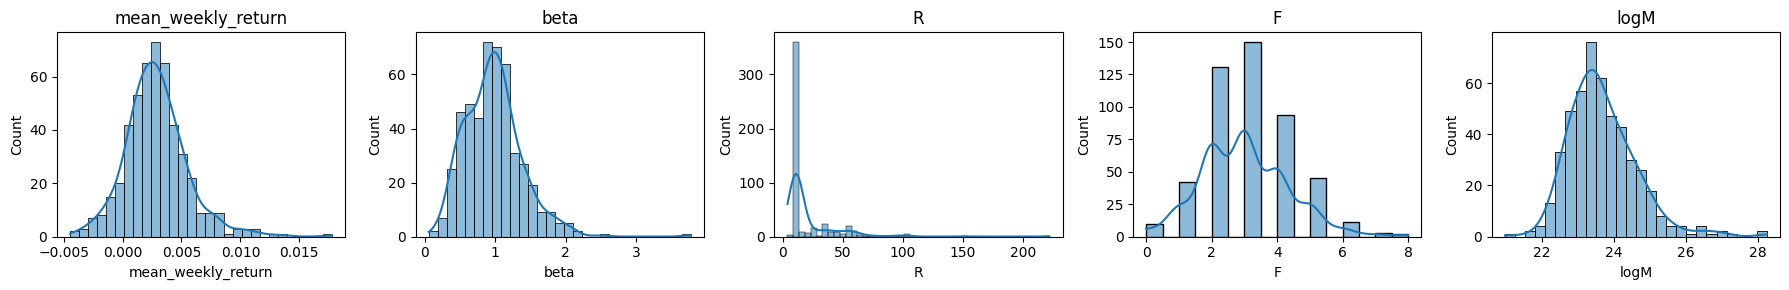

In [25]:

allX = pd.concat([X_rr_raw, X_rfm_raw], axis=1)
z = (allX - allX.mean()) / allX.std()
q1, q3 = allX.quantile(.25), allX.quantile(.75)
iqr_out = ((allX < q1 - 1.5 * (q3 - q1)) | (allX > q3 + 1.5 * (q3 - q1))).sum()
print('Outliers |z|>3:', (z.abs() > 3).sum().to_dict()); print('Outliers IQR rule:', iqr_out.to_dict())

fig, axes = plt.subplots(1, 5, figsize=(18, 3))
for ax, c in zip(axes, allX.columns):
    sns.histplot(allX[c], kde=True, ax=ax); ax.set_title(c)
plt.tight_layout(); plt.savefig('outputs/feature_distributions.png', dpi=150); plt.show()

In [26]:

sc = lambda df: pd.DataFrame(StandardScaler().fit_transform(df), index=df.index, columns=df.columns)
X_rr, X_rfm = sc(X_rr_raw), sc(X_rfm_raw)
print(X_rr.shape, X_rfm.shape, '| same shares:', X_rr.index.equals(X_rfm.index))

(488, 2) (488, 3) | same shares: True



Task 2.2 – Agglomerative clustering (Ward, Euclidean)

In [27]:
def agg_diag(X, ks=range(2, 9)):
    rows = []
    for k in ks:
        lab = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)   # ward = Euclidean only
        sizes = sorted(np.bincount(lab), reverse=True)
        rows.append({'k': k, 'silhouette': silhouette_score(X, lab), 'min_size': min(sizes), 'sizes': sizes})
    return pd.DataFrame(rows)

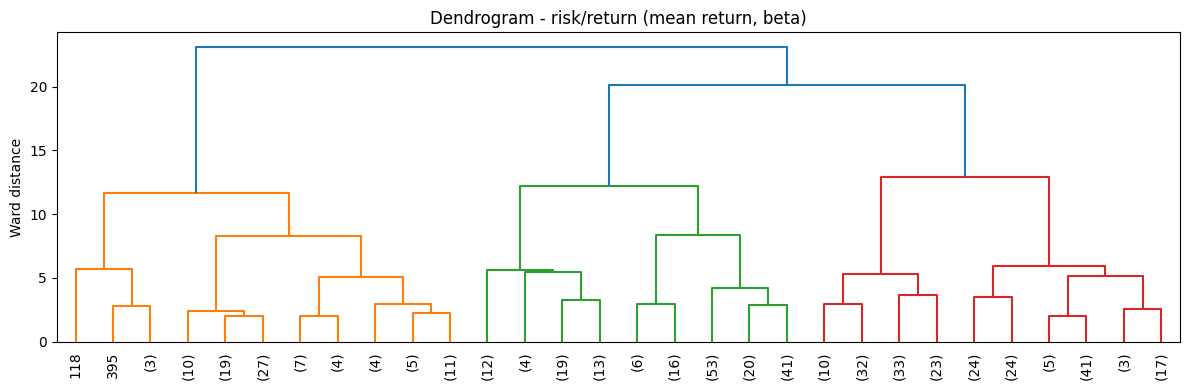

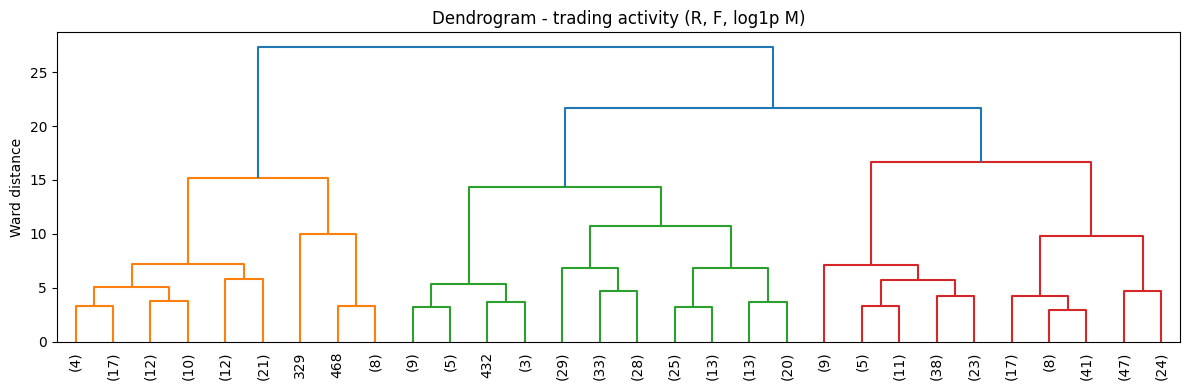

Ward - risk/return


,k,silhouette,min_size,sizes
0,2,0.339888,92,"[396, 92]"
1,3,0.292905,92,"[212, 184, 92]"
2,4,0.265427,92,"[184, 114, 98, 92]"
3,5,0.287282,48,"[136, 114, 98, 92, 48]"
4,6,0.304064,5,"[136, 114, 98, 87, 48, 5]"
5,7,0.306064,5,"[114, 114, 98, 87, 48, 22, 5]"
6,8,0.313846,5,"[114, 114, 98, 56, 48, 31, 22, 5]"


Ward - RFM


,k,silhouette,min_size,sizes
0,2,0.369340,86,"[402, 86]"
1,3,0.261434,86,"[223, 179, 86]"
2,4,0.251355,86,"[179, 137, 86, 86]"
3,5,0.270088,10,"[179, 137, 86, 76, 10]"
4,6,0.291391,10,"[161, 137, 86, 76, 18, 10]"
5,7,0.280443,10,"[137, 90, 86, 76, 71, 18, 10]"
6,8,0.281642,1,"[137, 90, 86, 76, 71, 18, 9, 1]"


In [28]:
def plot_dendro(X, title, fname):
    Z = linkage(X, method='ward', metric='euclidean')
    plt.figure(figsize=(12, 4))
    dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, show_leaf_counts=True)
    plt.title(title); plt.ylabel('Ward distance'); plt.tight_layout()
    plt.savefig(fname, dpi=150); plt.show()

plot_dendro(X_rr, 'Dendrogram - risk/return (mean return, beta)', 'outputs/dendrogram_risk_return.png')
plot_dendro(X_rfm, 'Dendrogram - trading activity (R, F, log1p M)', 'outputs/dendrogram_rfm.png')

agg_rr_diag, agg_rfm_diag = agg_diag(X_rr), agg_diag(X_rfm)
print('Ward - risk/return'); display(agg_rr_diag)
print('Ward - RFM'); display(agg_rfm_diag)

Task 2.3 – K-means

In [29]:
def km_diag(X, ks=range(2, 9)):
    rows = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
        sizes = sorted(np.bincount(km.labels_), reverse=True)
        rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(X, km.labels_),
                     'min_size': min(sizes), 'sizes': sizes})
    return pd.DataFrame(rows)

km_rr_diag, km_rfm_diag = km_diag(X_rr), km_diag(X_rfm)
print('K-means - risk/return'); display(km_rr_diag)
print('K-means - RFM'); display(km_rfm_diag)



K-means - risk/return


,k,inertia,silhouette,min_size,sizes
0,2,625.010434,0.386804,143,"[345, 143]"
1,3,464.070835,0.327815,119,"[203, 166, 119]"
2,4,373.953761,0.326067,40,"[162, 154, 132, 40]"
3,5,311.854206,0.338879,28,"[164, 127, 114, 55, 28]"
4,6,267.455411,0.335789,5,"[145, 132, 108, 56, 42, 5]"
5,7,228.707030,0.355360,16,"[144, 87, 79, 76, 48, 38, 16]"
6,8,196.031464,0.357569,5,"[139, 82, 76, 71, 48, 37, 30, 5]"


K-means - RFM


,k,inertia,silhouette,min_size,sizes
0,2,1071.585297,0.423769,68,"[420, 68]"
1,3,800.746441,0.325091,63,"[274, 151, 63]"
2,4,612.475070,0.341383,61,"[214, 122, 91, 61]"
3,5,517.074772,0.357967,11,"[200, 122, 87, 68, 11]"
4,6,439.829795,0.345333,11,"[143, 120, 106, 68, 40, 11]"
5,7,390.891264,0.340496,1,"[139, 119, 103, 65, 46, 15, 1]"
6,8,343.594208,0.342583,1,"[151, 105, 89, 65, 48, 18, 11, 1]"


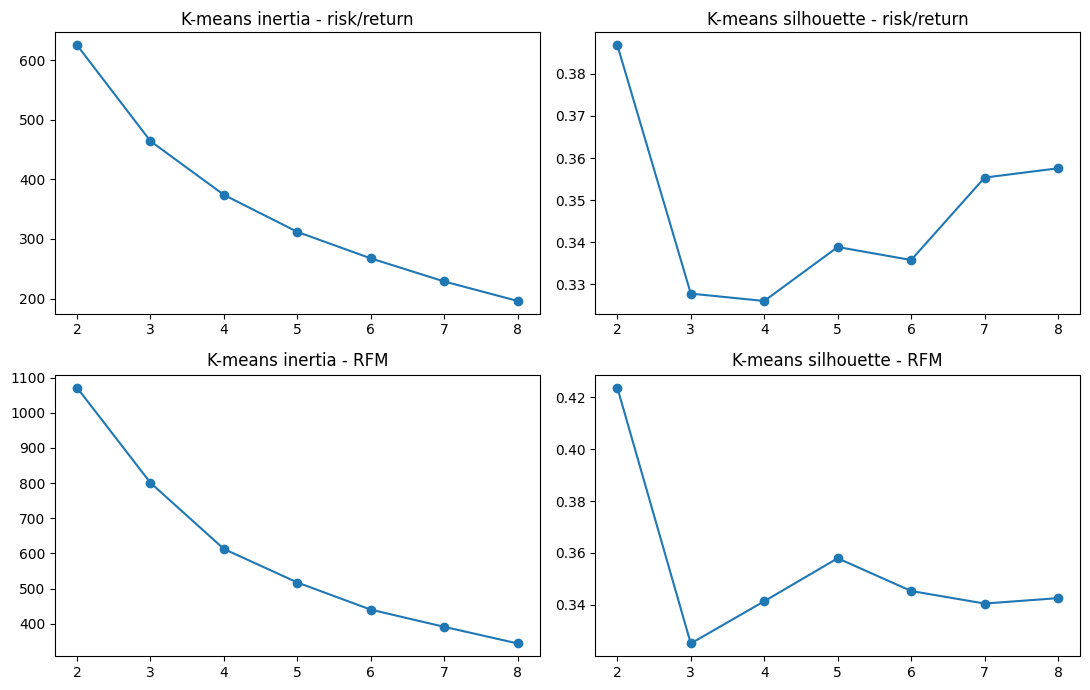

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for i, (name, d) in enumerate([('risk/return', km_rr_diag), ('RFM', km_rfm_diag)]):
    axes[i, 0].plot(d.k, d.inertia, 'o-'); axes[i, 0].set_title(f'K-means inertia - {name}')
    axes[i, 1].plot(d.k, d.silhouette, 'o-'); axes[i, 1].set_title(f'K-means silhouette - {name}')
plt.tight_layout(); plt.savefig('outputs/kmeans_diagnostics.png', dpi=150); plt.show()

Choose the cluster counts

In [31]:
def pick_k(d, n, min_share=0.05):
    ok = d[d.min_size >= min_share * n]
    ok = ok if len(ok) else d
    return int(ok.loc[ok.silhouette.idxmax(), 'k'])

n = len(X_rr)
K = {'agg_rr': pick_k(agg_rr_diag, n), 'km_rr': pick_k(km_rr_diag, n),
     'agg_rfm': pick_k(agg_rfm_diag, n), 'km_rfm': pick_k(km_rfm_diag, n)}
print('Selected k:', K)

Selected k: {'agg_rr': 2, 'km_rr': 2, 'agg_rfm': 2, 'km_rfm': 2}


Task 2.4 – Final models, profiles in original units, 2-D visualisation, algorithm comparison

In [32]:
def by_size(lab):
    order = pd.Series(lab).value_counts().index
    return pd.Series(lab).map({old: new for new, old in enumerate(order)}).values

labels = pd.DataFrame(index=X_rr.index)
labels['agg_rr']  = by_size(AgglomerativeClustering(n_clusters=K['agg_rr'], linkage='ward').fit_predict(X_rr))
labels['km_rr']   = by_size(KMeans(n_clusters=K['km_rr'], n_init=20, random_state=SEED).fit_predict(X_rr))
labels['agg_rfm'] = by_size(AgglomerativeClustering(n_clusters=K['agg_rfm'], linkage='ward').fit_predict(X_rfm))
labels['km_rfm']  = by_size(KMeans(n_clusters=K['km_rfm'], n_init=20, random_state=SEED).fit_predict(X_rfm))

full = feat_valid.join(labels)

def profile(lab, cols):
    g = full.groupby(lab)[cols]
    return g.mean().add_suffix('_mean').join(g.median().add_suffix('_median')).join(g.size().rename('n'))

for lab in ['agg_rr', 'km_rr']:
    print(lab); display(profile(lab, ['mean_weekly_return', 'beta']))
for lab in ['agg_rfm', 'km_rfm']:
    print(lab); display(profile(lab, ['R', 'F', 'M']))

agg_rr


,mean_weekly_return_mean,beta_mean,mean_weekly_return_median,beta_median,n
agg_rr,,,,,
0,0.002053,0.898545,0.002100,0.884962,396
1,0.006321,1.298084,0.005503,1.217711,92


km_rr


,mean_weekly_return_mean,beta_mean,mean_weekly_return_median,beta_median,n
km_rr,,,,,
0,0.001832,0.817762,0.001921,0.840681,345
1,0.005330,1.350487,0.004861,1.278113,143


agg_rfm


,R_mean,F_mean,M_mean,R_median,F_median,M_median,n
agg_rfm,,,,,,,
0,12.557214,3.203980,3.738926e+10,11.0,3.0,1.539575e+10,402
1,57.000000,1.976744,4.824805e+10,54.0,2.0,2.145008e+10,86


km_rfm


,R_mean,F_mean,M_mean,R_median,F_median,M_median,n
km_rfm,,,,,,,
0,13.435714,3.183333,3.260527e+10,11.0,3.0,1.556962e+10,420
1,63.338235,1.779412,8.067057e+10,55.0,2.0,2.225004e+10,68


In [33]:
def by_size(lab):
    order = pd.Series(lab).value_counts().index
    return pd.Series(lab).map({old: new for new, old in enumerate(order)}).values

labels = pd.DataFrame(index=X_rr.index)
labels['agg_rr']  = by_size(AgglomerativeClustering(n_clusters=K['agg_rr'], linkage='ward').fit_predict(X_rr))
labels['km_rr']   = by_size(KMeans(n_clusters=K['km_rr'], n_init=20, random_state=SEED).fit_predict(X_rr))
labels['agg_rfm'] = by_size(AgglomerativeClustering(n_clusters=K['agg_rfm'], linkage='ward').fit_predict(X_rfm))
labels['km_rfm']  = by_size(KMeans(n_clusters=K['km_rfm'], n_init=20, random_state=SEED).fit_predict(X_rfm))

full = feat_valid.join(labels)

def profile(lab, cols):
    g = full.groupby(lab)[cols]
    return g.mean().add_suffix('_mean').join(g.median().add_suffix('_median')).join(g.size().rename('n'))

for lab in ['agg_rr', 'km_rr']:
    print(lab); display(profile(lab, ['mean_weekly_return', 'beta']))
for lab in ['agg_rfm', 'km_rfm']:
    print(lab); display(profile(lab, ['R', 'F', 'M']))

agg_rr


,mean_weekly_return_mean,beta_mean,mean_weekly_return_median,beta_median,n
agg_rr,,,,,
0,0.002053,0.898545,0.002100,0.884962,396
1,0.006321,1.298084,0.005503,1.217711,92


km_rr


,mean_weekly_return_mean,beta_mean,mean_weekly_return_median,beta_median,n
km_rr,,,,,
0,0.001832,0.817762,0.001921,0.840681,345
1,0.005330,1.350487,0.004861,1.278113,143


agg_rfm


,R_mean,F_mean,M_mean,R_median,F_median,M_median,n
agg_rfm,,,,,,,
0,12.557214,3.203980,3.738926e+10,11.0,3.0,1.539575e+10,402
1,57.000000,1.976744,4.824805e+10,54.0,2.0,2.145008e+10,86


km_rfm


,R_mean,F_mean,M_mean,R_median,F_median,M_median,n
km_rfm,,,,,,,
0,13.435714,3.183333,3.260527e+10,11.0,3.0,1.556962e+10,420
1,63.338235,1.779412,8.067057e+10,55.0,2.0,2.225004e+10,68


In [34]:
pca = PCA(n_components=2, random_state=SEED).fit(X_rfm)
P = pd.DataFrame(pca.transform(X_rfm), index=X_rfm.index, columns=['PC1', 'PC2'])
print('PCA explained variance:', pca.explained_variance_ratio_.round(3))
print('PCA loadings:'); display(pd.DataFrame(pca.components_.T, index=X_rfm.columns, columns=['PC1', 'PC2']))


PCA explained variance: [0.458 0.336]
PCA loadings:


,PC1,PC2
R,0.711334,0.022898
F,-0.649526,0.403299
logM,0.268551,0.914782


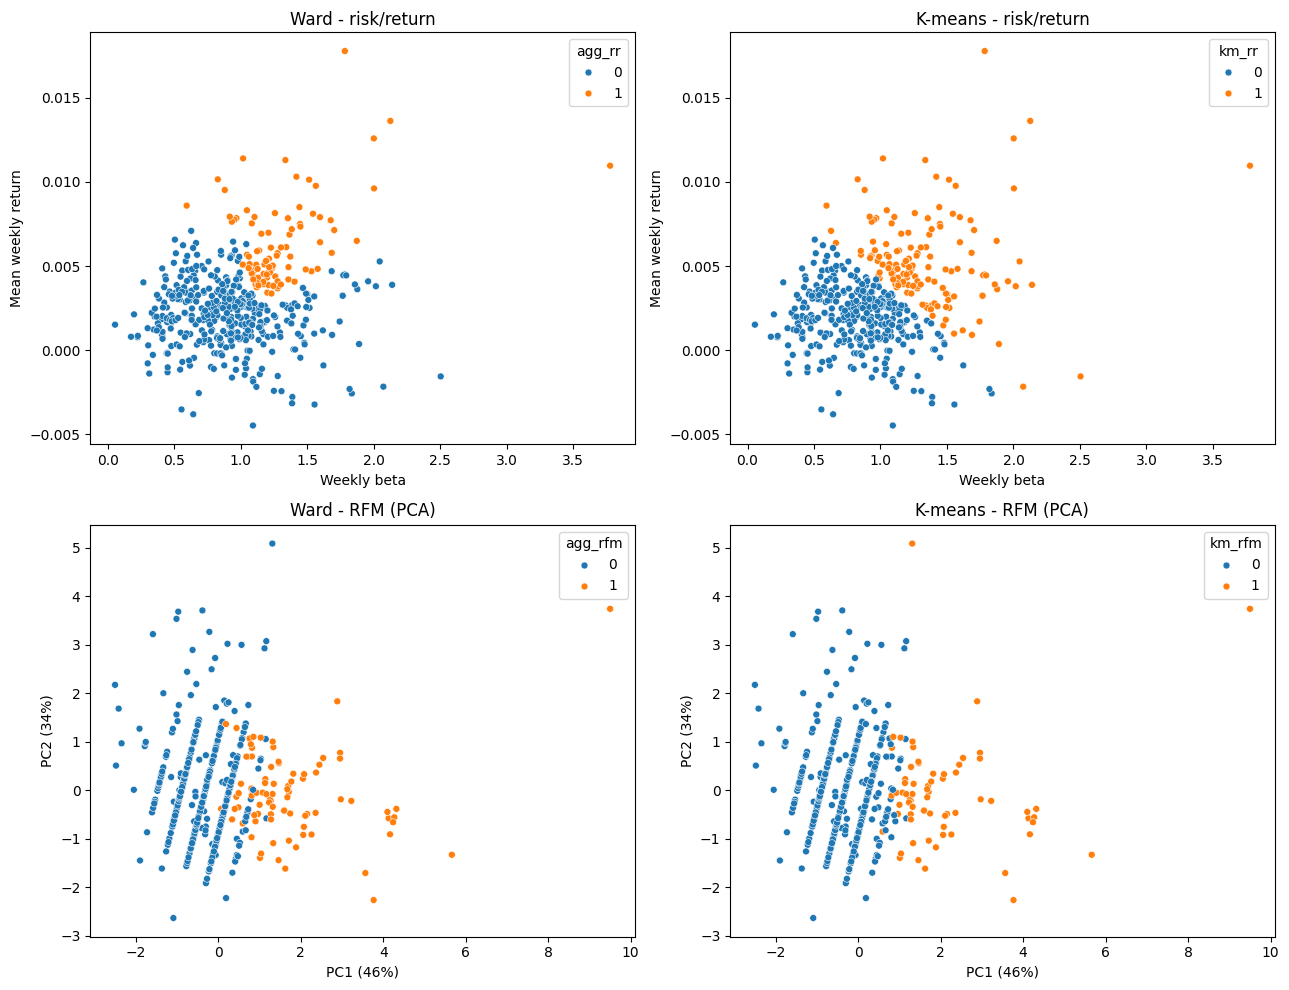

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, lab, title in [(axes[0, 0], 'agg_rr', 'Ward - risk/return'), (axes[0, 1], 'km_rr', 'K-means - risk/return')]:
    sns.scatterplot(x=full['beta'], y=full['mean_weekly_return'], hue=full[lab], palette='tab10', s=25, ax=ax)
    ax.set_xlabel('Weekly beta'); ax.set_ylabel('Mean weekly return'); ax.set_title(title)
for ax, lab, title in [(axes[1, 0], 'agg_rfm', 'Ward - RFM (PCA)'), (axes[1, 1], 'km_rfm', 'K-means - RFM (PCA)')]:
    sns.scatterplot(x=P['PC1'], y=P['PC2'], hue=full[lab], palette='tab10', s=25, ax=ax)
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})'); ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})'); ax.set_title(title)
plt.tight_layout(); plt.savefig('outputs/cluster_scatter.png', dpi=150); plt.show()


In [36]:
print('ARI Ward vs K-means (risk/return):', round(adjusted_rand_score(labels.agg_rr, labels.km_rr), 3))
print('ARI Ward vs K-means (RFM):        ', round(adjusted_rand_score(labels.agg_rfm, labels.km_rfm), 3))
print('ARI risk/return vs RFM (Ward):    ', round(adjusted_rand_score(labels.agg_rr, labels.agg_rfm), 3))
print('Silhouette final solutions:', {c: round(silhouette_score(X_rr if c.endswith('rr') else X_rfm, labels[c]), 3) for c in labels})
display(pd.crosstab(labels.agg_rr, labels.km_rr, rownames=['Ward rr'], colnames=['KMeans rr']))
display(pd.crosstab(labels.agg_rfm, labels.km_rfm, rownames=['Ward rfm'], colnames=['KMeans rfm']))

ARI Ward vs K-means (risk/return): 0.599
ARI Ward vs K-means (RFM):         0.78
ARI risk/return vs RFM (Ward):     0.03
Silhouette final solutions: {'agg_rr': np.float64(0.34), 'km_rr': np.float64(0.387), 'agg_rfm': np.float64(0.369), 'km_rfm': np.float64(0.424)}


KMeans rr,0,1
Ward rr,,
0,345,51
1,0,92


KMeans rfm,0,1
Ward rfm,,
0,400,2
1,20,66


Task 2.5 – RFM sensitivity and correlated inputs

,R,F,logM
R,1.000000,-0.346128,0.152835
F,-0.346128,1.000000,0.012848
logM,0.152835,0.012848,1.000000


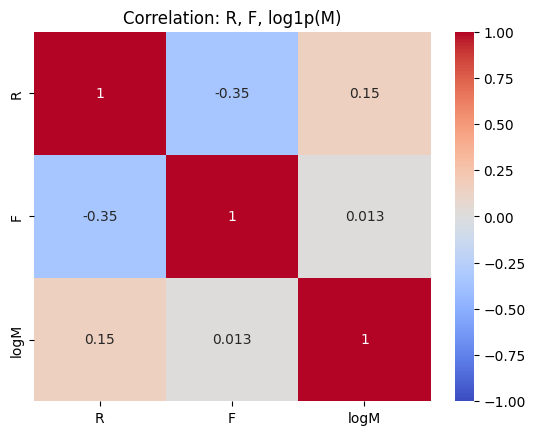

In [37]:

corr = X_rfm_raw.corr(); display(corr)
sns.heatmap(corr, annot=True, vmin=-1, vmax=1, cmap='coolwarm'); plt.title('Correlation: R, F, log1p(M)')
plt.savefig('outputs/rfm_correlation.png', dpi=150, bbox_inches='tight'); plt.show()

In [38]:
# Share of total variance carried by each principal direction of the standardised RFM features
eig = np.sort(np.linalg.eigvalsh(corr.values))[::-1]
print('Variance share per principal direction:', (eig / eig.sum()).round(3))

Variance share per principal direction: [0.458 0.336 0.206]


2.5.2 Removal of Monetary

In [39]:

X_rf = sc(X_rfm_raw[['R', 'F']])
lab_rf = by_size(AgglomerativeClustering(n_clusters=K['agg_rfm'], linkage='ward').fit_predict(X_rf))
full['agg_rf_only'] = lab_rf
print('Same shares:', len(X_rf) == len(X_rfm), '| k =', K['agg_rfm'])
print('ARI full RFM vs R,F only:', round(adjusted_rand_score(labels.agg_rfm, lab_rf), 3))
print('Silhouette R,F only:', round(silhouette_score(X_rf, lab_rf), 3))
display(pd.crosstab(labels.agg_rfm, lab_rf, rownames=['Ward RFM'], colnames=['Ward R,F only']))

Same shares: True | k = 2
ARI full RFM vs R,F only: 0.923
Silhouette R,F only: 0.521


"Ward R,F only",0,1
Ward RFM,,
0,396,6
1,2,84


In [40]:
print('Traded value (M, USD) by cluster - full RFM');   display(full.groupby('agg_rfm')['M'].agg(['median', 'mean', 'count']))
print('Traded value (M, USD) by cluster - R,F only');   display(full.groupby('agg_rf_only')['M'].agg(['median', 'mean', 'count']))
print('Spearman corr of M with R and F:'); display(feat_valid[['R', 'F', 'M']].corr(method='spearman')['M'])

Traded value (M, USD) by cluster - full RFM


,median,mean,count
agg_rfm,,,
0,1.539575e+10,3.738926e+10,402
1,2.145008e+10,4.824805e+10,86


Traded value (M, USD) by cluster - R,F only


,median,mean,count
agg_rf_only,,,
0,1.546039e+10,3.773977e+10,398
1,2.048974e+10,4.621541e+10,90


Spearman corr of M with R and F:


,M
R,0.137980
F,-0.048274
M,1.000000


Task 3 Business Intelligence and Critical Review

3.2.1 Cluster Profiles and Sector Composition

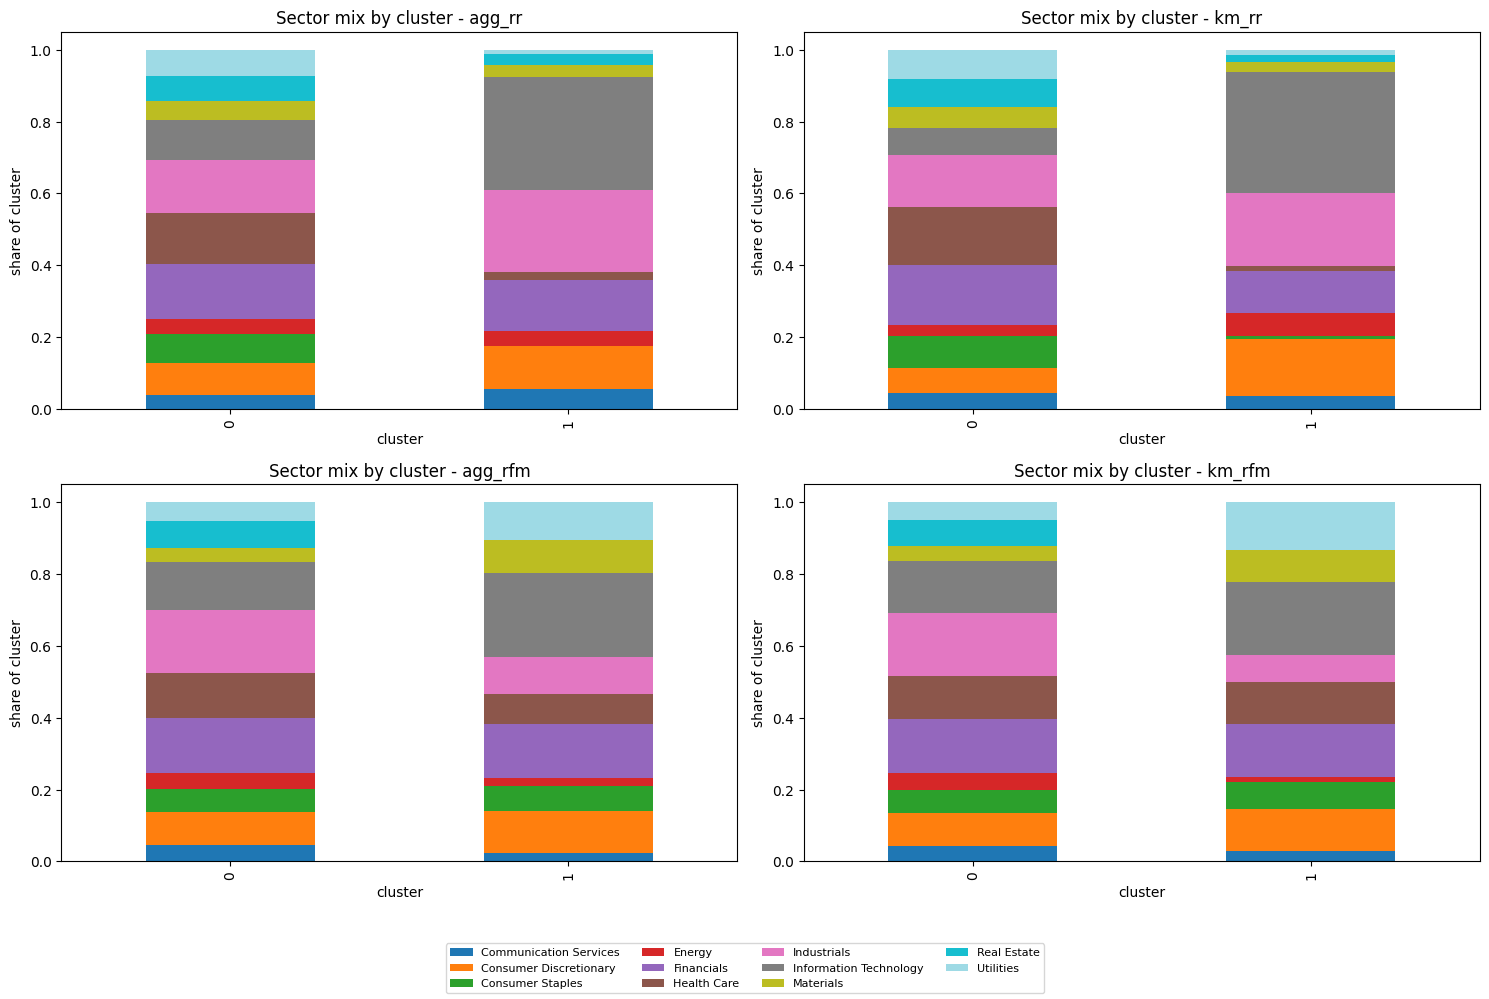

sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
agg_rr,,,,,,,,,,,
0,15,36,32,16,61,56,58,45,21,27,29
1,5,11,0,4,13,2,21,29,3,3,1


sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
agg_rfm,,,,,,,,,,,
0,18,37,26,18,61,51,70,54,16,30,21
1,2,10,6,2,13,7,9,20,8,0,9


In [41]:

full['sector'] = feat_valid['sector']
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, lab in zip(axes.ravel(), ['agg_rr', 'km_rr', 'agg_rfm', 'km_rfm']):
    ct = pd.crosstab(full[lab], full['sector'], normalize='index')
    ct.plot(kind='bar', stacked=True, ax=ax, legend=False, colormap='tab20')
    ax.set_title(f'Sector mix by cluster - {lab}'); ax.set_ylabel('share of cluster'); ax.set_xlabel('cluster')
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=4, fontsize=8); plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig('outputs/sector_composition.png', dpi=150); plt.show()
display(pd.crosstab(full['agg_rr'], full['sector']))
display(pd.crosstab(full['agg_rfm'], full['sector']))

In [42]:

display(full.groupby(['agg_rr', 'agg_rfm']).size().unstack(fill_value=0))

full.to_csv('outputs/feature_table_with_clusters.csv')
meta = {'observation_date': str(obs_date.date()), 'study_period': [START, END + ' (exclusive)'],
        'weekly_observations': int(n_obs), 'shares_requested': int(len(sp500_df)), 'shares_clustered': int(len(full)),
        'rfm_settings': {'baseline_sessions': BASE, 'window_sessions': WIN, 'multiplier': MULT},
        'selected_k': K, 'seed': SEED, 'n_init': 20,
        'versions': {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
                     'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__},
        'ticker_list_retrieved': str(sp500_df['retrieval_date'].iloc[0])}
json.dump(meta, open('outputs/run_metadata.json', 'w'), indent=2)
print(json.dumps(meta, indent=2))

agg_rfm,0,1
agg_rr,,
0,330,66
1,72,20


{
  "observation_date": "2024-12-31",
  "study_period": [
    "2021-01-01",
    "2025-01-01 (exclusive)"
  ],
  "weekly_observations": 207,
  "shares_requested": 503,
  "shares_clustered": 488,
  "rfm_settings": {
    "baseline_sessions": 20,
    "window_sessions": 60,
    "multiplier": 2
  },
  "selected_k": {
    "agg_rr": 2,
    "km_rr": 2,
    "agg_rfm": 2,
    "km_rfm": 2
  },
  "seed": 42,
  "n_init": 20,
  "versions": {
    "python": "3.13.18",
    "pandas": "2.2.3",
    "numpy": "2.4.6",
    "scikit-learn": "1.6.1",
    "scipy": "1.16.3"
  },
  "ticker_list_retrieved": "2026-11-22"
}


In [43]:

for lab in ['agg_rr', 'km_rr', 'agg_rfm', 'km_rfm']:
    print(f'\nSector percentage within {lab} clusters:')
    display((pd.crosstab(full[lab], full['sector'], normalize='index') * 100).round(1))



Sector percentage within agg_rr clusters:


sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
agg_rr,,,,,,,,,,,
0,3.8,9.1,8.1,4.0,15.4,14.1,14.6,11.4,5.3,6.8,7.3
1,5.4,12.0,0.0,4.3,14.1,2.2,22.8,31.5,3.3,3.3,1.1



Sector percentage within km_rr clusters:


sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
km_rr,,,,,,,,,,,
0,4.3,7.0,9.0,3.2,16.5,16.2,14.5,7.5,5.8,7.8,8.1
1,3.5,16.1,0.7,6.3,11.9,1.4,20.3,33.6,2.8,2.1,1.4



Sector percentage within agg_rfm clusters:


sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
agg_rfm,,,,,,,,,,,
0,4.5,9.2,6.5,4.5,15.2,12.7,17.4,13.4,4.0,7.5,5.2
1,2.3,11.6,7.0,2.3,15.1,8.1,10.5,23.3,9.3,0.0,10.5



Sector percentage within km_rfm clusters:


sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
km_rfm,,,,,,,,,,,
0,4.3,9.3,6.4,4.5,15.2,11.9,17.6,14.3,4.3,7.1,5.0
1,2.9,11.8,7.4,1.5,14.7,11.8,7.4,20.6,8.8,0.0,13.2


In [44]:

for lab, cols in [('agg_rr', ['mean_weekly_return', 'beta']), ('km_rr', ['mean_weekly_return', 'beta']),
                  ('agg_rfm', ['R', 'F', 'M']), ('km_rfm', ['R', 'F', 'M'])]:
    print(f'\nOriginal-unit profile: {lab}')
    display(profile(lab, cols).round(3))



Original-unit profile: agg_rr


,mean_weekly_return_mean,beta_mean,mean_weekly_return_median,beta_median,n
agg_rr,,,,,
0,0.002,0.899,0.002,0.885,396
1,0.006,1.298,0.006,1.218,92



Original-unit profile: km_rr


,mean_weekly_return_mean,beta_mean,mean_weekly_return_median,beta_median,n
km_rr,,,,,
0,0.002,0.818,0.002,0.841,345
1,0.005,1.350,0.005,1.278,143



Original-unit profile: agg_rfm


,R_mean,F_mean,M_mean,R_median,F_median,M_median,n
agg_rfm,,,,,,,
0,12.557,3.204,3.738926e+10,11.0,3.0,1.539575e+10,402
1,57.000,1.977,4.824805e+10,54.0,2.0,2.145008e+10,86



Original-unit profile: km_rfm


,R_mean,F_mean,M_mean,R_median,F_median,M_median,n
km_rfm,,,,,,,
0,13.436,3.183,3.260527e+10,11.0,3.0,1.556962e+10,420
1,63.338,1.779,8.067057e+10,55.0,2.0,2.225004e+10,68
